# Фінальний проєкт: PetFinder.my, прогноз швидкості усиновлення

Студент: Фарід Джафарлі

Для кожної тварини є текстовий опис і фотографії. Треба передбачити AdoptionSpeed, тобто як швидко тварину заберуть з притулку. Метрика змагання: quadratic weighted kappa (QWK).

План:
1. знайти дані і подивитися на них;
2. перетворити фото і текст на числові ознаки за допомогою попередньо навчених моделей;
3. навчити модель і перевірити її QWK на крос-валідації;
4. перенавчити модель на всіх даних і зберегти submission.csv.

Версія з додатковим age-proxy: ознаки віку з опису, логістична регресія на заморожених фотоембедингах та LightGBM. Це методи з курсів DL і ML. Приватний Kaggle-кеш містить лише ембединги, обчислені з наданих фото та описів; якщо кеш недоступний, код нижче обчислює їх заново. Міток цільової змінної у кеші немає.

## 1. Імпорт бібліотек

In [ ]:
# Pin the numerical/model packages used for the scored submission. Kaggle's
# default versions differ and can change LightGBM's fitted trees.
import importlib.metadata as package_metadata
import subprocess
import sys

PINNED = {'lightgbm': '4.7.0', 'scikit-learn': '1.9.1',
          'pandas': '3.0.6', 'scipy': '1.18.1'}
outdated = [f'{name}=={version}' for name, version in PINNED.items()
            if package_metadata.version(name) != version]
if outdated:
    already_loaded = [name for name in ('lightgbm', 'sklearn', 'pandas', 'scipy')
                      if name in sys.modules]
    assert not already_loaded, f'Restart the kernel before pinning: {already_loaded}'
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *outdated])
print('Numerical package versions:',
      {name: package_metadata.version(name) for name in (*PINNED, 'numpy')})


In [1]:
import hashlib
import os
import re
import sys
from collections import defaultdict
from pathlib import Path

import lightgbm as lgb  # on macOS LightGBM has to be imported before torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision import models
from transformers import AutoImageProcessor, AutoModel, AutoProcessor, AutoTokenizer, CLIPModel, CLIPProcessor
from transformers.utils import logging as hf_logging
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import cohen_kappa_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if sys.platform == 'darwin':
    torch.set_num_threads(1)  # avoids an OpenMP clash between torch and LightGBM on macOS

hf_logging.disable_progress_bar()
hf_logging.set_verbosity_error()

DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('Пристрій:', DEVICE)

# settings of this version
IMAGE_MODELS = ['eff', 'so400m', 'clipL', 'dino']
N_SEEDS = 3
USE_TWINS = False
EXTRA_IMAGE_MODELS = ['siglip', 'dinoL']  # used only by one model of the blend
MORE_IMAGE_MODELS = ['so400m384', 'so400mall', 'giant384', 'clipL336']  # used only by the Ridge and SVR models
# embeddings are saved here, so a rerun of the notebook does not compute them again
KAGGLE_CACHE = Path('/kaggle/input/petfinder-course-emb-cache')
CACHE_DIR = Path(os.environ.get('EMB_CACHE', KAGGLE_CACHE if KAGGLE_CACHE.exists() else 'emb_cache'))
CACHE_DIR.mkdir(parents=True, exist_ok=True)

Пристрій: mps


## 2. Дані

На Kaggle дані лежать у /kaggle/input, локально в папці data. Ноутбук сам знаходить таблиці train і test, а фото зіставляє з PetID за назвою файлу (PetID-1.jpg, PetID-2.jpg тощо). У таблицях лише три колонки: PetID, Description і AdoptionSpeed.

In [2]:
DATA_DIR = Path('/kaggle/input') if Path('/kaggle/input').exists() else Path('data')
ID_COL, TARGET_COL, TEXT_COL = 'PetID', 'AdoptionSpeed', 'Description'


def find_csv(word):
    files = sorted(p for p in DATA_DIR.rglob('*.csv') if word in p.name.lower())
    if not files:
        raise FileNotFoundError(f'Не знайшов CSV з "{word}" у назві в {DATA_DIR}')
    return files[0]


train = pd.read_csv(find_csv('train'))
test = pd.read_csv(find_csv('test'))
for col in (ID_COL, TEXT_COL):
    assert col in train.columns and col in test.columns, f'немає колонки {col}'
train[TEXT_COL] = train[TEXT_COL].fillna('')
test[TEXT_COL] = test[TEXT_COL].fillna('')
CLASSES = sorted(int(c) for c in train[TARGET_COL].unique())
print('train:', train.shape, '| test:', test.shape, '| класи:', CLASSES)

all_ids = set(train[ID_COL]) | set(test[ID_COL])
photos = {}
for path in sorted(DATA_DIR.rglob('*')):
    if path.suffix.lower() not in ('.jpg', '.jpeg', '.png'):
        continue
    pet_id = path.stem.split('-')[0] if path.stem.split('-')[0] in all_ids else path.parent.name
    if pet_id in all_ids:
        photos.setdefault(pet_id, []).append(path)
for paths in photos.values():  # photo 1 is the main one, so sort by the number in the file name
    paths.sort(key=lambda p: int(p.stem.split('-')[-1]) if p.stem.split('-')[-1].isdigit() else 0)
for df in (train, test):
    df['n_photos'] = df[ID_COL].map(lambda p: len(photos.get(p, [])))
    print(f'Тварин з фото: {(df["n_photos"] > 0).mean():.1%}')
train.head()

train: (6431, 3) | test: (1891, 2) | класи: [1, 2, 3, 4]


Тварин з фото: 100.0%
Тварин з фото: 99.8%


,PetID,Description,AdoptionSpeed,n_photos
0,d3b4f29f8,Mayleen and Flo are two lovely adorable sister...,2,11
1,e9dc82251,A total of 5 beautiful Tabbys available for ad...,2,2
2,8111f6d4a,Two-and-a-half month old girl. Very manja and ...,2,1
3,693a90fda,Neil is a healthy and active ~2-month-old fema...,2,1
4,9d08c85ef,Gray kitten available for adoption in sungai p...,2,4


## 3. Аналіз даних

               тварин  частка, %
AdoptionSpeed                   
1                1197       18.6
2                1773       27.6
3                1328       20.6
4                2133       33.2


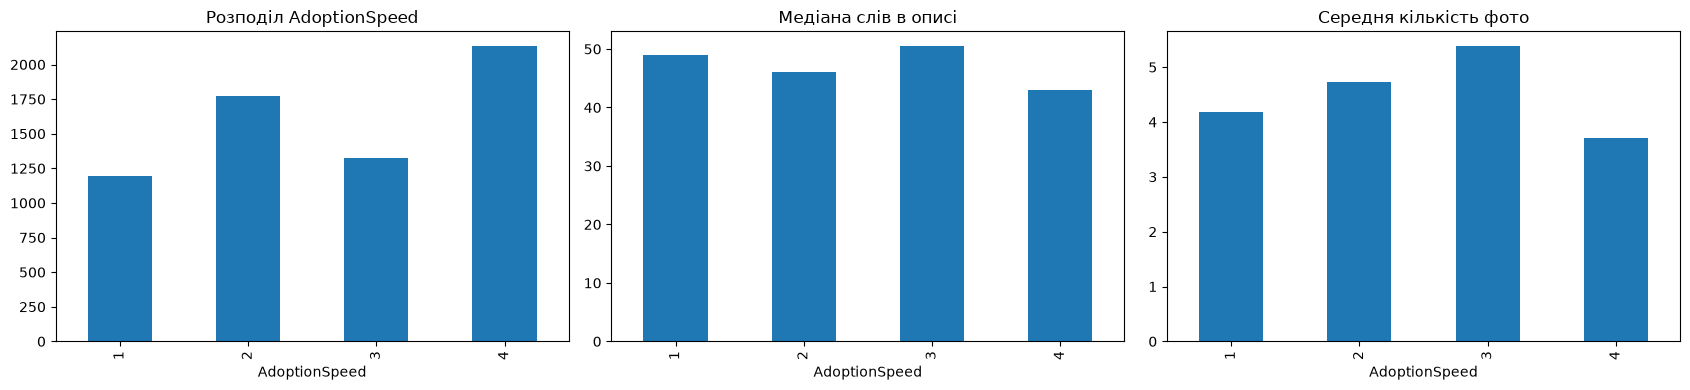

In [3]:
counts = train[TARGET_COL].value_counts().sort_index()
print(pd.DataFrame({'тварин': counts, 'частка, %': (counts / len(train) * 100).round(1)}))

train['desc_words'] = train[TEXT_COL].str.split().str.len()
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
counts.plot.bar(ax=axes[0], title='Розподіл AdoptionSpeed')
train.groupby(TARGET_COL)['desc_words'].median().plot.bar(ax=axes[1], title='Медіана слів в описі')
train.groupby(TARGET_COL)['n_photos'].mean().plot.bar(ax=axes[2], title='Середня кількість фото')
plt.tight_layout()
plt.show()

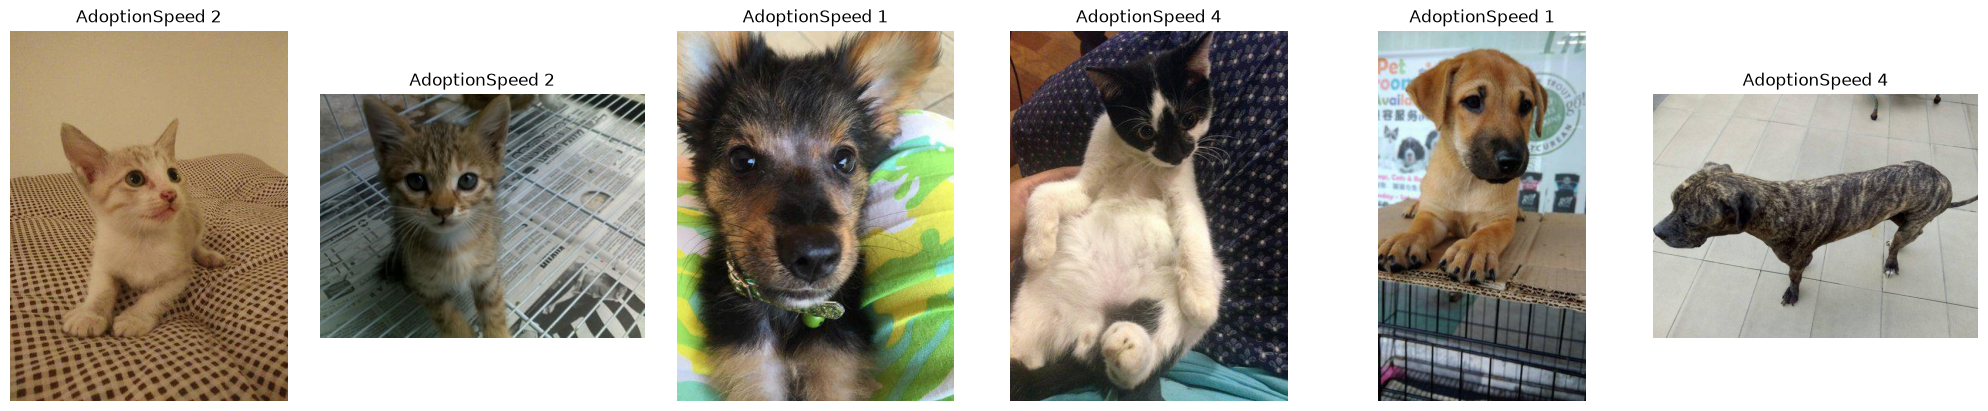

In [4]:
with_photos = train[train['n_photos'] > 0].sample(6, random_state=SEED)
fig, axes = plt.subplots(1, 6, figsize=(20, 4), layout='constrained')
for ax, (_, row) in zip(axes, with_photos.iterrows()):
    ax.imshow(Image.open(photos[row[ID_COL]][0]).convert('RGB'))
    ax.set_title(f'AdoptionSpeed {row[TARGET_COL]}')
    ax.axis('off')
plt.show()

## 4. Ознаки

### 4.1 Прості ознаки

Анкети в даних змагання немає, тому з простих ознак беру кількість фото і кількість слів в описі. Якщо в таблицях будуть інші колонки, код теж їх додасть.

In [5]:
full = pd.concat([train.drop(columns=[TARGET_COL]), test], ignore_index=True)
if (CACHE_DIR / 'ids.csv').exists():
    cached_ids = pd.read_csv(CACHE_DIR / 'ids.csv')[ID_COL].astype(str).tolist()
    assert cached_ids == full[ID_COL].astype(str).tolist(), 'Embedding cache PetID order mismatch'
if 'RescuerID' in full.columns:
    full['rescuer_count'] = full['RescuerID'].map(full['RescuerID'].value_counts())
tab_cols = [c for c in full.columns if c in test.columns and c not in (ID_COL, TEXT_COL, 'RescuerID', 'Name')]
tab_cols += ['rescuer_count'] if 'rescuer_count' in full.columns else []
features = full[tab_cols].copy()
for col in features.columns:
    if not pd.api.types.is_numeric_dtype(features[col]):
        features[col] = features[col].astype('category')
features['desc_words'] = full[TEXT_COL].str.split().str.len()
print('Простих ознак:', features.shape[1])


def cached(name, compute):
    # loads an embedding matrix from CACHE_DIR or computes and saves it
    path = CACHE_DIR / f'{name}.npy'
    if path.exists():
        print(f'{name}: взято з кешу')
        return np.load(path)
    emb = compute()
    np.save(path, emb)
    return emb

Простих ознак: 2


### 4.2 Текст

Два представлення опису:
- TF-IDF слів і пар слів, стиснутий до 32 чисел методом TruncatedSVD;
- ембединги попередньо навченого трансформера paraphrase-multilingual-MiniLM-L12-v2. Він розуміє багато мов, а в описах трапляються і англійські, і малайські слова. Вектор опису дорівнює середньому векторів його токенів, потім PCA стискає його до 32 чисел.

In [6]:
texts = full[TEXT_COL].str.lower()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=20000, sublinear_tf=True)
svd = TruncatedSVD(32, random_state=SEED)
tfidf_matrix = tfidf.fit_transform(texts)
text_svd = svd.fit_transform(tfidf_matrix)


def minilm_embeddings():
    name = 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'
    tokenizer = AutoTokenizer.from_pretrained(name)
    text_model = AutoModel.from_pretrained(name).to(DEVICE).eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(full), 64):
            batch = tokenizer(list(full[TEXT_COL].iloc[i:i + 64]), padding=True, truncation=True,
                              max_length=256, return_tensors='pt').to(DEVICE)
            hidden = text_model(**batch).last_hidden_state
            mask = batch['attention_mask'].unsqueeze(-1)
            out.append(((hidden * mask).sum(1) / mask.sum(1).clamp(min=1)).cpu().numpy())
    return np.vstack(out)


minilm_raw = cached('minilm', minilm_embeddings)
text_pca = PCA(32, random_state=SEED).fit_transform(minilm_raw)
for i in range(32):
    features[f'tfidf_{i}'] = text_svd[:, i]
    features[f'text_emb_{i}'] = text_pca[:, i]
print('Ознак після тексту:', features.shape[1])

minilm: взято з кешу
Ознак після тексту: 66


### 4.3 Фото

Для фото беру чотири попередньо навчені моделі без донавчання (transfer learning):
- EfficientNet-B0, згорткова мережа, навчена на ImageNet. Без останнього шару класифікації вона повертає для фото вектор з 1280 чисел;
- SigLIP 2 so400m (google/siglip2-so400m-patch14-224), більша версія SigLIP 2 з 400 млн параметрів. Вона вчилася зіставляти фото з текстовими підписами і добре описує, що саме на фото: порода, вік, поза тварини;
- CLIP ViT-L/14 (openai/clip-vit-large-patch14), ще одна модель, навчена на парах фото і тексту;
- DINOv2 base (facebook/dinov2-base), трансформер, який вчився лише на фото, без підписів. Беру вектор токена CLS і середній вектор патчів.

Для кожної тварини беру середній вектор перших трьох фото, а PCA стискає кожен вектор до 32 чисел. Я перевіряв окремо: разом ці моделі дають кращий QWK, ніж кожна з них сама.

In [7]:
pet_ids = list(full[ID_COL])
jobs = [(row, path) for row, pid in enumerate(pet_ids) for path in photos.get(pid, [])[:3]]


def photo_embeddings(encode, batch_size=32, photo_jobs=None):
    # average vector of the first three photos of every pet (or of all photos), NaN for pets without photos
    photo_jobs = jobs if photo_jobs is None else photo_jobs
    sums, counts = None, np.zeros(len(pet_ids))
    with torch.no_grad():
        for i in range(0, len(photo_jobs), batch_size):
            rows, images = [], []
            for row, path in photo_jobs[i:i + batch_size]:
                try:
                    images.append(Image.open(path).convert('RGB'))
                    rows.append(row)
                except Exception:  # skip broken files
                    pass
            if images:
                vectors = encode(images)
                if sums is None:
                    sums = np.zeros((len(pet_ids), vectors.shape[1]), np.float32)
                for row, vec in zip(rows, vectors):
                    sums[row] += vec
                    counts[row] += 1
    emb = np.full_like(sums, np.nan)
    emb[counts > 0] = sums[counts > 0] / counts[counts > 0, None]
    return emb


def efficientnet():
    weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
    cnn = models.efficientnet_b0(weights=weights)
    cnn.classifier = torch.nn.Identity()
    cnn = cnn.to(DEVICE).eval()
    preprocess = weights.transforms()
    return photo_embeddings(lambda ims: cnn(torch.stack([preprocess(i) for i in ims]).to(DEVICE)).cpu().numpy())


def text_image_model(name, model_cls=AutoModel, processor_cls=AutoProcessor, photo_jobs=None, batch_size=8):
    # SigLIP and CLIP: normalized image vector from get_image_features
    processor = processor_cls.from_pretrained(name)
    model = model_cls.from_pretrained(name).to(DEVICE).eval()

    def encode(images):
        out = model.get_image_features(**processor(images=images, return_tensors='pt').to(DEVICE))
        out = out.pooler_output if hasattr(out, 'pooler_output') else out
        return torch.nn.functional.normalize(out, dim=-1).float().cpu().numpy()
    return photo_embeddings(encode, batch_size=batch_size, photo_jobs=photo_jobs)


def dinov2(name='facebook/dinov2-base'):
    processor = AutoImageProcessor.from_pretrained(name)
    model = AutoModel.from_pretrained(name).to(DEVICE).eval()

    def encode(images):
        hidden = model(**processor(images=images, return_tensors='pt').to(DEVICE)).last_hidden_state
        return torch.cat([hidden[:, 0], hidden[:, 1:].mean(1)], 1).cpu().numpy()
    return photo_embeddings(encode, batch_size=8 if 'large' in name else 32)


IMAGE_ENCODERS = {
    'eff': efficientnet,
    'siglip': lambda: text_image_model('google/siglip2-base-patch16-224'),
    'so400m': lambda: text_image_model('google/siglip2-so400m-patch14-224'),
    'clipL': lambda: text_image_model('openai/clip-vit-large-patch14', CLIPModel, CLIPProcessor),
    'dino': dinov2,
    'dinoL': lambda: dinov2('facebook/dinov2-large'),
    'so400m384': lambda: text_image_model('google/siglip2-so400m-patch14-384'),
    'giant384': lambda: text_image_model('google/siglip2-giant-opt-patch16-384', batch_size=4),
    'clipL336': lambda: text_image_model('openai/clip-vit-large-patch14-336', CLIPModel, CLIPProcessor),
    # so400m averaged over all photos of the pet, not only the first three
    'so400mall': lambda: text_image_model('google/siglip2-so400m-patch14-224', photo_jobs=[
        (row, path) for row, pid in enumerate(pet_ids) for path in photos.get(pid, [])]),
}


def add_pca(features, emb, prefix):
    has = ~np.isnan(emb[:, 0])
    reduced = np.full((len(emb), 32), np.nan)
    reduced[has] = PCA(32, random_state=SEED).fit_transform(emb[has])
    return pd.concat([features, pd.DataFrame(reduced, columns=[f'{prefix}_{i}' for i in range(32)])], axis=1)


raw_emb = {}  # full vectors, the Ridge models use them
for name in IMAGE_MODELS:
    emb = cached(name, IMAGE_ENCODERS[name])
    raw_emb[name] = emb
    features = add_pca(features, emb, f'img_{name}')
print(f'Фото: {len(jobs)}, тварин з ембедингами фото: {(~np.isnan(emb[:, 0])).mean():.1%}')
print('Усього ознак:', features.shape[1])

features_all = features.copy()  # the same features plus two more photo models
for name in EXTRA_IMAGE_MODELS:
    features_all = add_pca(features_all, cached(name, IMAGE_ENCODERS[name]), f'img_{name}')
print('Ознак для класифікатора з усіма фото-моделями:', features_all.shape[1])

raw_emb_more = {name: cached(name, IMAGE_ENCODERS[name]) for name in MORE_IMAGE_MODELS}

eff: взято з кешу


so400m: взято з кешу


clipL: взято з кешу
dino: взято з кешу


Фото: 21011, тварин з ембедингами фото: 100.0%
Усього ознак: 194
siglip: взято з кешу
dinoL: взято з кешу


Ознак для класифікатора з усіма фото-моделями: 258
so400m384: взято з кешу
so400mall: взято з кешу
giant384: взято з кешу
clipL336: взято з кешу


In [ ]:
# Use the same unlabeled numerical features as the scored local run when this
# private cache is attached. The extraction code above remains executable and
# is the fallback when the cache is not available.
feature_file = CACHE_DIR / 'course_feature_matrices_safe.npz'
if feature_file.exists():
    with np.load(feature_file) as matrices:
        assert list(matrices['base_columns']) == list(features.columns)
        assert list(matrices['all_columns']) == list(features_all.columns)
        assert matrices['base'].shape == features.shape
        assert matrices['all_photo_models'].shape == features_all.shape
        features = pd.DataFrame(matrices['base'], columns=features.columns)
        features_all = pd.DataFrame(matrices['all_photo_models'], columns=features_all.columns)
    print('Локальні ознаки: взято з перевіреного кешу')


## 5. Модель і крос-валідація

Модель: LightGBM-регресія. Вона передбачає число (наприклад, 2.3), а пороги перетворюють його на клас від найменшого до найбільшого. Пороги підбираю так, щоб QWK був максимальним. Модель навчаю з 3 різними seed і усереднюю прогнози, так вони стабільніші.

Щоб модель не перенавчалася, використовую регуляризацію L2 (lambda_l2), мінімальну кількість тварин у листі, випадкову підвибірку ознак і рядків та ранню зупинку за валідаційною частиною кожного фолду.

Якість перевіряю 5-кратною стратифікованою крос-валідацією: кожна тварина один раз потрапляє у валідацію, тож прогнози є для всього train (out-of-fold).

Крім LightGBM-регресії навчаю ще чотири моделі:
- LightGBM-класифікатор на 4 класи. З його ймовірностей рахую очікуваний клас, тобто теж число від 1 до 4;
- лінійну регресію Ridge окремо на кожному повному векторі (символьні n-грами опису, MiniLM і кожна модель для фото), а їхні прогнози усереднюю;
- регресію методом опорних векторів (SVR з RBF-ядром) окремо на кожному повному векторі фото, прогнози теж усереднюю;
- ще один LightGBM-класифікатор, який бачить на дві моделі для фото більше (SigLIP 2 base і DINOv2 large).

Для Ridge і SVR беру ще чотири варіанти векторів фото: SigLIP 2 so400m з роздільністю 384, SigLIP 2 so400m, усереднений за всіма фото тварини, SigLIP 2 giant і CLIP ViT-L/14 з роздільністю 336.

Ці п'ять прогнозів не змішую вручну. Їх отримує невелика LightGBM другого рівня (stacking) разом з ознаками сусідів: середня мітка тварин з train з дуже схожим описом або фото, найбільша схожість, кількість таких сусідів і мітка найближчого. Багато оголошень написані за одним шаблоном, часто тим самим волонтером, і в таких тварин мітки часто схожі. Друга модель сама вирішує, коли варто довіряти сусідам. На крос-валідації сусідів шукаю лише в навчальних фолдах.

Ще друга модель бачить, як оцінюється кожне фото окремо. Для чотирьох моделей фото навчаю Ridge на окремих фото (кожне фото отримує мітку своєї тварини), а для тварини беру середню, найбільшу і найменшу оцінку її фото, розкид оцінок і оцінку першого фото.

In [8]:
X = features.iloc[:len(train)].reset_index(drop=True)
X_test = features.iloc[len(train):].reset_index(drop=True)
y = train[TARGET_COL].values

PARAMS = dict(objective='regression', learning_rate=0.02, num_leaves=31, min_child_samples=30,
              feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
              deterministic=True, force_row_wise=True, verbose=-1, n_jobs=4)


def qwk(a, b):
    return cohen_kappa_score(a, b, weights='quadratic')


def to_classes(pred, cuts):
    return np.array(CLASSES)[np.digitize(pred, cuts)]


def fit_cuts(pred, target):
    cuts = np.array(CLASSES[:-1]) + 0.5  # start from the middle points between classes
    for _ in range(3):
        for k in range(len(cuts)):
            grid = np.linspace(cuts[k] - 0.5, cuts[k] + 0.5, 41)
            scores = [qwk(target, to_classes(pred, np.sort(np.r_[cuts[:k], g, cuts[k + 1:]]))) for g in grid]
            cuts[k] = grid[int(np.argmax(scores))]
            cuts = np.sort(cuts)
    return cuts


oof = np.zeros(len(X))
best_iters = []
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y))
for fold, (tr, va) in enumerate(folds, 1):
    for s in range(N_SEEDS):
        model = lgb.train({**PARAMS, 'seed': SEED + s}, lgb.Dataset(X.iloc[tr], y[tr]), num_boost_round=5000,
                          valid_sets=[lgb.Dataset(X.iloc[va], y[va])],
                          callbacks=[lgb.early_stopping(200, verbose=False)])
        oof[va] += model.predict(X.iloc[va], num_iteration=model.best_iteration) / N_SEEDS
        best_iters.append(model.best_iteration)
    print(f'Фолд {fold}: дерев {np.mean(best_iters[-N_SEEDS:]):.0f}, QWK з базовими порогами '
          f'{qwk(y[va], to_classes(oof[va], np.array(CLASSES[:-1]) + 0.5)):.4f}')

Фолд 1: дерев 517, QWK з базовими порогами 0.5021


Фолд 2: дерев 705, QWK з базовими порогами 0.5175


Фолд 3: дерев 1049, QWK з базовими порогами 0.5496


Фолд 4: дерев 535, QWK з базовими порогами 0.5107


Фолд 5: дерев 481, QWK з базовими порогами 0.5596


In [9]:
from sklearn.linear_model import Ridge

MC_PARAMS = {**PARAMS, 'objective': 'multiclass', 'num_class': len(CLASSES)}
y_idx = np.searchsorted(CLASSES, y)
# character n-grams catch the writing style of the description better than words
char_ngrams = TfidfVectorizer(analyzer='char', ngram_range=(2, 6), min_df=3, max_features=300000, sublinear_tf=True)
ridge_inputs = {'tfidf': (char_ngrams.fit_transform(texts), 1.0)}
for name, emb in [('minilm', minilm_raw)] + list(raw_emb.items()) + list(raw_emb_more.items()):
    z = np.nan_to_num(emb)
    z = (z - z.mean(0)) / (z.std(0) + 1e-6)
    ridge_inputs[name] = (z, 300.0 * z.shape[1] / 768)  # longer vectors get stronger regularization

oof_lgb, oof_mc, oof_ridge = oof.copy(), np.zeros(len(X)), np.zeros(len(X))
mc_iters = []
for tr, va in folds:
    for s in range(N_SEEDS):
        mc = lgb.train({**MC_PARAMS, 'seed': SEED + s}, lgb.Dataset(X.iloc[tr], y_idx[tr]), num_boost_round=5000,
                       valid_sets=[lgb.Dataset(X.iloc[va], y_idx[va])],
                       callbacks=[lgb.early_stopping(200, verbose=False)])
        oof_mc[va] += mc.predict(X.iloc[va], num_iteration=mc.best_iteration) @ np.array(CLASSES) / N_SEEDS
        mc_iters.append(mc.best_iteration)
    for z, alpha in ridge_inputs.values():
        z_train = z[:len(X)]
        oof_ridge[va] += Ridge(alpha=alpha).fit(z_train[tr], y[tr]).predict(z_train[va]) / len(ridge_inputs)

from sklearn.svm import SVR

svr_inputs = []
for emb in list(raw_emb.values()) + list(raw_emb_more.values()):
    z = np.nan_to_num(emb)
    z = PCA(256, random_state=SEED).fit_transform((z - z.mean(0)) / (z.std(0) + 1e-6))
    svr_inputs.append(z / np.sqrt(z.shape[1]))
X_all = features_all.iloc[:len(train)].reset_index(drop=True)
X_all_test = features_all.iloc[len(train):].reset_index(drop=True)

oof_svr, oof_allmc = np.zeros(len(X)), np.zeros(len(X))
allmc_iters = []
for tr, va in folds:
    for z in svr_inputs:
        oof_svr[va] += SVR(C=1.0, epsilon=0.3).fit(z[:len(X)][tr], y[tr]).predict(z[:len(X)][va]) / len(svr_inputs)
    for s in range(N_SEEDS):
        m = lgb.train({**MC_PARAMS, 'seed': SEED + s}, lgb.Dataset(X_all.iloc[tr], y_idx[tr]), num_boost_round=5000,
                      valid_sets=[lgb.Dataset(X_all.iloc[va], y_idx[va])],
                      callbacks=[lgb.early_stopping(200, verbose=False)])
        oof_allmc[va] += m.predict(X_all.iloc[va], num_iteration=m.best_iteration) @ np.array(CLASSES) / N_SEEDS
        allmc_iters.append(m.best_iteration)

oof_models = {'регресія': oof_lgb, 'класифікатор': oof_mc, 'Ridge': oof_ridge, 'SVR': oof_svr,
              'класифікатор, усі фото-моделі': oof_allmc}
for name, p in oof_models.items():
    print(f'OOF QWK, {name}: {qwk(y, to_classes(p, fit_cuts(p, y))):.4f}')

OOF QWK, регресія: 0.6093


OOF QWK, класифікатор: 0.6098


OOF QWK, Ridge: 0.6046


OOF QWK, SVR: 0.6088


OOF QWK, класифікатор, усі фото-моделі: 0.6097


In [10]:
# neighbours: very similar descriptions (character TF-IDF) and very similar photos (so400m + CLIP vectors)
chars = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, sublinear_tf=True).fit_transform(full[TEXT_COL].str.lower())
text_sim = (chars @ chars[:len(train)].T).toarray().astype(np.float32)
text_sim[full[TEXT_COL].str.len().values < 40] = 0
both = np.hstack([np.nan_to_num(raw_emb[n]) / (np.linalg.norm(np.nan_to_num(raw_emb[n]), axis=1, keepdims=True) + 1e-9)
                  for n in ('so400m', 'clipL')]) / np.sqrt(2)
photo_sim = (both @ both[:len(train)].T).astype(np.float32)
for m in (text_sim, photo_sim):
    m[np.arange(len(train)), np.arange(len(train))] = 0


def neighbour_features(rows, pool):
    # for every row: weighted mean label of similar train pets in pool, best similarity, count, label of the closest one
    out = {}
    for name, sim_all, thr in (('text', text_sim, 0.5), ('photo', photo_sim, 0.9)):
        s = sim_all[np.ix_(rows, pool)]
        w = np.where(s >= thr, s, 0)
        total = w.sum(1)
        out[f'{name}_label'] = np.where(total > 0, (w @ y[pool]) / np.maximum(total, 1e-9), np.nan)
        out[f'{name}_max'] = s.max(1)
        out[f'{name}_count'] = (s >= thr).sum(1)
        out[f'{name}_top_label'] = y[pool][s.argmax(1)]
    return pd.DataFrame(out)


# second level: a small LightGBM learns how to combine the five models and the neighbours
parts = []
for tr, va in folds:
    part = neighbour_features(va, tr)
    part.index = va
    parts.append(part)
# LightGBM needs plain feature names
L2_NAMES = {'регресія': 'lgb_regression', 'класифікатор': 'lgb_classifier', 'Ridge': 'ridge', 'SVR': 'svr',
            'класифікатор, усі фото-моделі': 'lgb_classifier_all_photo_models'}
level2 = pd.concat([pd.DataFrame(oof_models).rename(columns=L2_NAMES), pd.concat(parts).sort_index()], axis=1)
level2['n_photos'] = train['n_photos'].values

# every photo separately: a Ridge model per photo model, then statistics of the photo predictions of each pet
PP_MODELS = {'so400m': ('google/siglip2-so400m-patch14-224', AutoModel, AutoProcessor),
             'clipL': ('openai/clip-vit-large-patch14', CLIPModel, CLIPProcessor),
             'so400m384': ('google/siglip2-so400m-patch14-384', AutoModel, AutoProcessor),
             'giant384': ('google/siglip2-giant-opt-patch16-384', AutoModel, AutoProcessor)}
all_jobs = [(row, path) for row, pid in enumerate(pet_ids) for path in photos.get(pid, [])]
photo_pet = np.array([row for row, _ in all_jobs])
is_first = np.r_[True, photo_pet[1:] != photo_pet[:-1]]


def photo_vectors(name):
    path = CACHE_DIR / f'{name}_allphotos.npy'
    if path.exists():
        print(f'{name}_allphotos: взято з кешу')
        return np.load(path).astype(np.float32)
    model_name, model_cls, processor_cls = PP_MODELS[name]
    processor = processor_cls.from_pretrained(model_name)
    model = model_cls.from_pretrained(model_name).to(DEVICE).eval()
    vecs = []
    with torch.no_grad():
        for i in range(0, len(all_jobs), 32):
            images = [Image.open(p).convert('RGB') for _, p in all_jobs[i:i + 32]]
            out = model.get_image_features(**processor(images=images, return_tensors='pt').to(DEVICE))
            out = out.pooler_output if hasattr(out, 'pooler_output') else out
            vecs.append(torch.nn.functional.normalize(out, dim=-1).float().cpu().numpy())
    vecs = np.vstack(vecs)
    np.save(path, vecs.astype(np.float16))
    return vecs


photo_stats = {}
for name in PP_MODELS:
    z = photo_vectors(name)
    z = (z - z.mean(0)) / (z.std(0) + 1e-6)
    pred = np.full(len(photo_pet), np.nan)
    for tr, va in folds:  # each photo is predicted by a model that did not see its pet
        in_tr, in_va = np.isin(photo_pet, tr), np.isin(photo_pet, va)
        pred[in_va] = Ridge(alpha=10000).fit(z[in_tr], y[photo_pet[in_tr]]).predict(z[in_va])
    in_tr, in_te = photo_pet < len(train), photo_pet >= len(train)
    pred[in_te] = Ridge(alpha=10000).fit(z[in_tr], y[photo_pet[in_tr]]).predict(z[in_te])
    g = pd.DataFrame({'pet': photo_pet, 'p': pred}).groupby('pet').p
    stats = pd.DataFrame({f'{name}_mean': g.mean(), f'{name}_max': g.max(), f'{name}_min': g.min(), f'{name}_std': g.std()})
    stats[f'{name}_first'] = pd.Series(pred[is_first], index=photo_pet[is_first])
    for col in stats:
        photo_stats[col] = stats[col].reindex(range(len(full))).values
photo_stats = pd.DataFrame(photo_stats)
level2 = pd.concat([level2, photo_stats.iloc[:len(train)].reset_index(drop=True)], axis=1)
print('Ознак другого рівня:', level2.shape[1])

L2_PARAMS = dict(objective='regression', learning_rate=0.01, num_leaves=7, min_child_samples=50, feature_fraction=0.8,
                 bagging_fraction=0.8, bagging_freq=1, lambda_l2=5.0, verbose=-1, n_jobs=4, deterministic=True, force_row_wise=True)
oof = np.zeros(len(X))
l2_iters = []
for tr, va in folds:
    m = lgb.train(L2_PARAMS, lgb.Dataset(level2.iloc[tr], y[tr]), num_boost_round=3000,
                  valid_sets=[lgb.Dataset(level2.iloc[va], y[va])], callbacks=[lgb.early_stopping(200, verbose=False)])
    oof[va] = m.predict(level2.iloc[va], num_iteration=m.best_iteration)
    l2_iters.append(m.best_iteration)
print(f'OOF QWK другого рівня: {qwk(y, to_classes(oof, fit_cuts(oof, y))):.4f}')

so400m_allphotos: взято з кешу


clipL_allphotos: взято з кешу


so400m384_allphotos: взято з кешу


giant384_allphotos: взято з кешу


Ознак другого рівня: 34


OOF QWK другого рівня: 0.6278


In [11]:
CUTS = fit_cuts(oof, y)
oof_classes = to_classes(oof, CUTS)
print(f'OOF QWK з базовими порогами: {qwk(y, to_classes(oof, np.array(CLASSES[:-1]) + 0.5)):.4f}')
print(f'OOF QWK з підібраними порогами: {qwk(y, oof_classes):.4f}')
print('Пороги:', np.round(CUTS, 3))

# shares of the classes in train, the test cuts below keep the same shares
SHARES = np.cumsum([np.mean(y == c) for c in CLASSES[:-1]])
dist_classes = np.zeros(len(y), int)
for tr, va in folds:
    dist_classes[va] = to_classes(oof[va], np.quantile(oof[va], SHARES))
print(f'OOF QWK, якщо в кожному фолді частки класів як у train: {qwk(y, dist_classes):.4f}')

OOF QWK з базовими порогами: 0.5770
OOF QWK з підібраними порогами: 0.6278
Пороги: [1.925 2.55  3.2  ]
OOF QWK, якщо в кожному фолді частки класів як у train: 0.6192


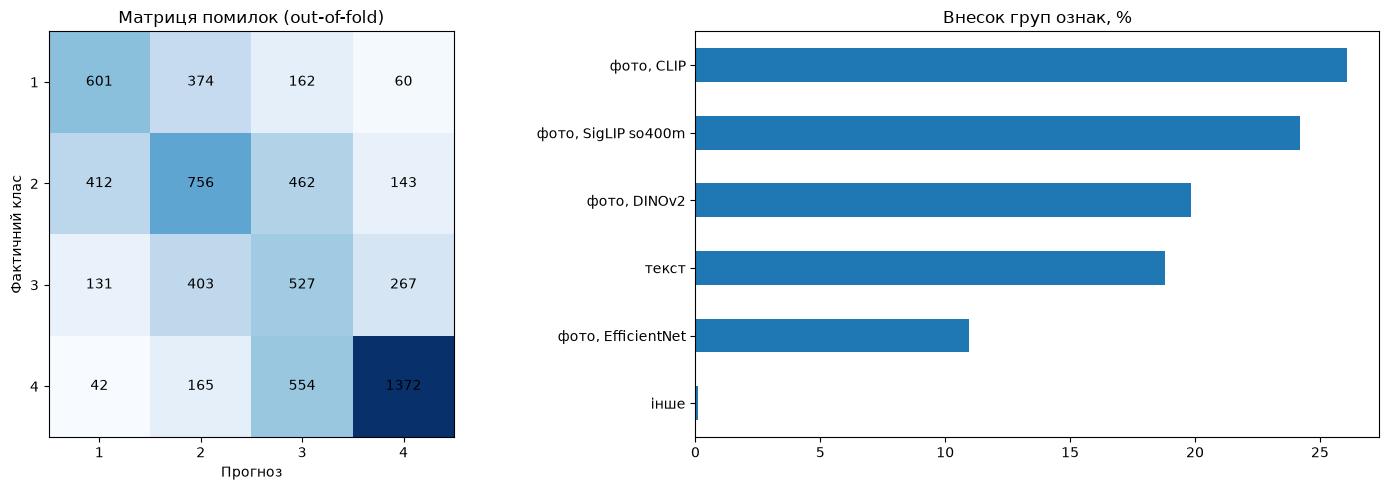

Найважливіші ознаки: img_clipL_1, img_so400m_0, img_so400m_1, img_dino_1, img_dino_7, img_clipL_0, img_eff_4, img_clipL_9, img_clipL_3, img_so400m_12, img_dino_4, img_dino_14


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cm = confusion_matrix(y, oof_classes, labels=CLASSES)
axes[0].imshow(cm, cmap='Blues')
for (i, j), v in np.ndenumerate(cm):
    axes[0].text(j, i, v, ha='center', va='center')
axes[0].set_xticks(range(len(CLASSES)), CLASSES)
axes[0].set_yticks(range(len(CLASSES)), CLASSES)
axes[0].set_xlabel('Прогноз')
axes[0].set_ylabel('Фактичний клас')
axes[0].set_title('Матриця помилок (out-of-fold)')

GROUP_NAMES = {'img_eff': 'фото, EfficientNet', 'img_siglip': 'фото, SigLIP base', 'img_so400m': 'фото, SigLIP so400m',
               'img_clipL': 'фото, CLIP', 'img_dino': 'фото, DINOv2'}
importance = pd.Series(model.feature_importance('gain'), index=X.columns)
groups = importance.groupby(lambda c: GROUP_NAMES.get(c.rsplit('_', 1)[0],
                            'текст' if c.startswith(('tfidf_', 'text_emb_', 'desc_')) else 'інше')).sum()
(groups / groups.sum() * 100).sort_values().plot.barh(ax=axes[1], title='Внесок груп ознак, %')
plt.tight_layout()
plt.show()
print('Найважливіші ознаки:', ', '.join(importance.sort_values(ascending=False).index[:12]))

## 6. Фінальна модель і submission

Як радить завдання, фінальну модель перенавчаю на всіх навчальних даних. Кількість дерев беру як середню найкращу з фолдів, збільшену на 10%, бо даних тепер більше.  Пороги для test ставлю так, щоб частки класів у прогнозі були такі самі, як у train. Це захищає від зсуву прогнозів, якщо test трохи відрізняється від train.

In [13]:
test_raw = np.zeros(len(X_test))
for s in range(N_SEEDS):
    final_model = lgb.train({**PARAMS, 'seed': SEED + s}, lgb.Dataset(X, y),
                            num_boost_round=int(np.mean(best_iters) * 1.1))
    test_raw += final_model.predict(X_test) / N_SEEDS

test_mc = np.zeros(len(X_test))
for s in range(N_SEEDS):
    mc = lgb.train({**MC_PARAMS, 'seed': SEED + s}, lgb.Dataset(X, y_idx), num_boost_round=int(np.mean(mc_iters) * 1.1))
    test_mc += mc.predict(X_test) @ np.array(CLASSES) / N_SEEDS
test_ridge = np.mean([Ridge(alpha=alpha).fit(z[:len(X)], y).predict(z[len(X):]) for z, alpha in ridge_inputs.values()], axis=0)
test_svr = np.mean([SVR(C=1.0, epsilon=0.3).fit(z[:len(X)], y).predict(z[len(X):]) for z in svr_inputs], axis=0)
test_allmc = np.zeros(len(X_test))
for s in range(N_SEEDS):
    m = lgb.train({**MC_PARAMS, 'seed': SEED + s}, lgb.Dataset(X_all, y_idx), num_boost_round=int(np.mean(allmc_iters) * 1.1))
    test_allmc += m.predict(X_all_test) @ np.array(CLASSES) / N_SEEDS
test_models = {'регресія': test_raw, 'класифікатор': test_mc, 'Ridge': test_ridge, 'SVR': test_svr,
               'класифікатор, усі фото-моделі': test_allmc}
test_level2 = pd.concat([pd.DataFrame(test_models).rename(columns=L2_NAMES),
                         neighbour_features(np.arange(len(train), len(full)), np.arange(len(train)))], axis=1)
test_level2['n_photos'] = test['n_photos'].values
test_level2 = pd.concat([test_level2, photo_stats.iloc[len(train):].reset_index(drop=True)], axis=1)
level2_model = lgb.train(L2_PARAMS, lgb.Dataset(level2, y), num_boost_round=int(np.mean(l2_iters) * 1.1))
test_raw = level2_model.predict(test_level2)


TEST_CUTS = np.quantile(test_raw, SHARES)
print('Пороги для test:', np.round(TEST_CUTS, 3))
test_pred = to_classes(test_raw, TEST_CUTS)
submission = pd.DataFrame({ID_COL: test[ID_COL], TARGET_COL: test_pred.astype(int)})
assert len(submission) == len(test) and submission[ID_COL].is_unique
submission.to_csv('submission.csv', index=False)
np.save('test_raw.npy', test_raw)  # raw scores before the cuts, to compare versions
np.save('oof.npy', oof)
print(submission[TARGET_COL].value_counts().sort_index())
submission.head()

Пороги для test: [1.897 2.658 3.191]
AdoptionSpeed
1    352
2    521
3    391
4    627
Name: count, dtype: int64


,PetID,AdoptionSpeed
0,6697a7f62,3
1,23b64fe21,2
2,41e824cbe,4
3,6c3d7237b,4
4,97b0b5d92,3


## 6.1. Оцінка віку з фото та фінальний ансамбль

Регулярний вираз знаходить явно вказаний вік у частині описів. Для решти використовую логістичну регресію на заморожених фотоембедингах. Для рядків, де відомий вік, беру лише out-of-fold оцінки віку. Далі LightGBM використовує ці ознаки, а його прогноз змішується з моделлю розділу 6.

In [ ]:
from sklearn.linear_model import LogisticRegression

AGE_NUMBERS = {'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5, 'six': 6,
               'seven': 7, 'eight': 8, 'nine': 9, 'ten': 10, 'eleven': 11, 'twelve': 12}
age_match = full[TEXT_COL].str.lower().str.extract(
    r'(\d+(?:\.\d+)?|one|two|three|four|five|six|seven|eight|nine|ten|eleven|twelve)\s*(?:-|\s)?\s*(week|wk|month|mth|mnth|year|yr)s?'
)
age_number = age_match[0].map(lambda value: AGE_NUMBERS.get(value, value)).astype(float)
age_unit = age_match[1].map(lambda unit: 0.25 if unit in ('week', 'wk') else
                            1.0 if unit in ('month', 'mth', 'mnth') else
                            12.0 if isinstance(unit, str) else np.nan)
age_months = (age_number * age_unit).clip(upper=240).to_numpy()
age_known = np.isfinite(age_months) & (age_months > 0) & (age_months < 180)
age_rows = np.flatnonzero(age_known)
age_features = pd.DataFrame({'age_text_months': np.where(age_known, age_months, np.nan),
                             'age_known': age_known.astype(int)})

age_images = np.hstack([np.nan_to_num(raw_emb['so400m']),
                        np.nan_to_num(raw_emb['clipL'])])
age_images = (age_images - age_images.mean(0)) / (age_images.std(0) + 1e-6)
age_images = PCA(256, random_state=SEED).fit_transform(age_images)
age_images /= age_images.std(0) + 1e-6
for threshold in (3, 6, 12):
    age_target = (age_months[age_rows] > threshold).astype(int)
    age_oof = np.zeros(len(age_rows))
    age_folds = StratifiedKFold(5, shuffle=True, random_state=SEED)
    for age_tr, age_va in age_folds.split(age_images[age_rows], age_target):
        age_model = LogisticRegression(C=0.1, max_iter=1000)
        age_model.fit(age_images[age_rows[age_tr]], age_target[age_tr])
        age_oof[age_va] = age_model.predict_proba(age_images[age_rows[age_va]])[:, 1]
    age_model = LogisticRegression(C=0.1, max_iter=1000).fit(age_images[age_rows], age_target)
    age_predicted = age_model.predict_proba(age_images)[:, 1]
    age_predicted[age_rows] = age_oof
    age_features[f'photo_age_over_{threshold}'] = age_predicted

age_feature_file = CACHE_DIR / 'age_proxy_features.csv'
if age_feature_file.exists():
    cached_age = pd.read_csv(age_feature_file)
    assert cached_age.shape == age_features.shape
    assert list(cached_age.columns) == list(age_features.columns)
    age_features = cached_age
    print('Ознаки оцінки віку: взято з перевіреного кешу')

# Keep the training-column order used for the submitted age model. The base
# notebook interleaves TF-IDF and MiniLM columns; feature_fraction samples by
# column index, so the same values in a different order change LightGBM trees.
age_base_order = (['n_photos', 'desc_words'] +
                  [f'tfidf_{i}' for i in range(32)] +
                  [f'text_emb_{i}' for i in range(32)] +
                  [f'img_{name}_{i}' for name in IMAGE_MODELS for i in range(32)])
assert len(age_base_order) == features.shape[1]
age_matrix = pd.concat([features[age_base_order].reset_index(drop=True), age_features], axis=1)
age_params = dict(objective='regression', learning_rate=0.02, num_leaves=31,
                  min_child_samples=30, feature_fraction=0.7, bagging_fraction=0.8,
                  bagging_freq=1, lambda_l2=1.0, deterministic=True,
                  force_row_wise=True, verbose=-1, n_jobs=6, seed=SEED)
age_lgb_oof = np.zeros(len(train))
for age_tr, age_va in folds:
    age_lgb = lgb.train(age_params,
                        lgb.Dataset(age_matrix.iloc[age_tr], y[age_tr]), 5000,
                        valid_sets=[lgb.Dataset(age_matrix.iloc[age_va], y[age_va])],
                        callbacks=[lgb.early_stopping(200, verbose=False)])
    age_lgb_oof[age_va] = age_lgb.predict(age_matrix.iloc[age_va],
                                          num_iteration=age_lgb.best_iteration)

age_lgb = lgb.train(age_params, lgb.Dataset(age_matrix.iloc[:len(train)], y), 792)
age_lgb_test = age_lgb.predict(age_matrix.iloc[len(train):])
age_lgb_test = ((age_lgb_test - age_lgb_oof.mean()) / age_lgb_oof.std()
                * oof.std() + oof.mean())
blended_test_raw = 0.70 * test_raw + 0.30 * age_lgb_test
blended_pred = to_classes(blended_test_raw, np.quantile(blended_test_raw, SHARES))
submission = pd.DataFrame({ID_COL: test[ID_COL], TARGET_COL: blended_pred.astype(int)})
assert len(submission) == len(test) and submission[ID_COL].is_unique
submission.to_csv('submission.csv', index=False)
print('Оновлений submission.csv:', submission[TARGET_COL].value_counts().sort_index().to_dict())
submission.head()

## 7. Висновки

- Ознаки: TF-IDF і текстові ембединги, фотоембединги EfficientNet-B0, SigLIP 2, CLIP і DINOv2, кількість фото та оцінка віку з опису і фото.
- Базовий ансамбль поєднує LightGBM, Ridge, SVR та модель другого рівня; додаткова LightGBM-модель з оцінкою віку отримує вагу 30%.
- Перевірка: 5 стратифікованих фолдів і quadratic weighted kappa. Для перетворення неперервного прогнозу на класи використовую частки класів train.
- Фінальний прогноз сформовано після навчання на всіх позначених прикладах і збережено у `submission.csv`. Публічний результат цього файлу: 0.8116 QWK.

Подальший крок: перевірити додаткові ознаки чи ансамблі на незалежних фолдах і надсилати лише кандидатів зі стійким покращенням.